# Plant Disease Detection: CNN · AlexNet · ResNet-50 · EfficientNetB0
**Paper:** Mishra et al. (2026) — *Deep learning-based disease detection in potato and mango leaves: a comparative study of CNN, AlexNet, ResNet, and EfficientNet* — Scientific Reports 16:2788  
**Framework:** TensorFlow / Keras  
**Dataset:** PlantVillage Potato (2,152 imgs, 3 classes) + Kaggle Mango Leaf (4,000 imgs, 8 classes) → **11 classes**

| Scenario | Augmentation |
|----------|--------------|
| Baseline | None (Resize + Normalize only) |
| Augmented | RandomFlip · RandomRotation ±20° · RandomZoom · RandomBrightness |

In [7]:
# ── Cell: Install dependencies ──────────────────────────────────────────────
!pip install -q openpyxl Pillow

In [8]:
# ── Cell: Imports ────────────────────────────────────────────────────────────
import os, random, warnings
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.applications import ResNet50, EfficientNetB0
from tensorflow.keras.applications.resnet50 import preprocess_input as resnet_preprocess
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score, recall_score, accuracy_score
)
from sklearn.model_selection import train_test_split
from collections import Counter
import openpyxl
from openpyxl import Workbook
from openpyxl.styles import Font, Alignment, PatternFill, Border, Side
from openpyxl.drawing.image import Image as XLImage
from openpyxl.utils import get_column_letter
warnings.filterwarnings('ignore')
print('TF version:', tf.__version__)

TF version: 2.19.0


In [ ]:
# ── Cell: Config & Seeds ─────────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

strategy = tf.distribute.MirroredStrategy()
n_gpus = strategy.num_replicas_in_sync
print(f"GPUs available: {n_gpus}")

# ── Kaggle dataset path ───────────────────────────────────────────────────────
DATASET_DIR = '/kaggle/input/datasets/tminhhi/finaldata/dataset_smartcrop_new'
OUTPUT_DIR  = '/kaggle/working'
os.makedirs(OUTPUT_DIR, exist_ok=True)

IMG_SIZE   = (224, 224)
BATCH_SIZE = 32
LR         = 1e-4
LR_FT      = 1e-5   # learning rate for fine-tuning phase

EPOCHS = {
    'cnn'              : 30,
    'alexnet'          : 35,
    'resnet_p1'        : 25,
    'resnet_p2'        : 10,
    'efficientnet_p1'  : 20,
    'efficientnet_p2'  : 10,
}
DROPOUT = {'cnn': 0.4, 'alexnet': 0.4, 'resnet': 0.3, 'efficientnet': 0.3}
PAPER_CITATION = 'Mishra et al. (2026) - Scientific Reports'

AUTOTUNE = tf.data.AUTOTUNE
print(f'Config OK | GPUs: {n_gpus}')

In [10]:
# ── Cell: Load & Split Dataset ───────────────────────────────────────────────
TRAIN_DIR = os.path.join(DATASET_DIR, 'train')
VAL_DIR   = os.path.join(DATASET_DIR, 'val')
TEST_DIR  = os.path.join(DATASET_DIR, 'test')

def collect_paths(root):
    paths, labels = [], []
    for cls in sorted(os.listdir(root)):
        cls_dir = os.path.join(root, cls)
        if not os.path.isdir(cls_dir):
            continue
        for fname in sorted(os.listdir(cls_dir)):
            if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
                paths.append(os.path.join(cls_dir, fname))
                labels.append(cls)
    return np.array(paths), np.array(labels)

train_paths_raw, train_labels_str = collect_paths(TRAIN_DIR)
val_paths_raw,   val_labels_str   = collect_paths(VAL_DIR)
test_paths_raw,  test_labels_str  = collect_paths(TEST_DIR)

CLASS_NAMES = sorted(set(train_labels_str.tolist()))
NUM_CLASSES = len(CLASS_NAMES)
label2idx   = {c: i for i, c in enumerate(CLASS_NAMES)}

X_train = train_paths_raw
y_train = np.array([label2idx[l] for l in train_labels_str])
X_val   = val_paths_raw
y_val   = np.array([label2idx[l] for l in val_labels_str])
X_test  = test_paths_raw
y_test  = np.array([label2idx[l] for l in test_labels_str])

print(f'Classes ({NUM_CLASSES}):', CLASS_NAMES)
print(f'Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}')

Classes (5): ['anthracnose', 'healthy', 'leaf_curl', 'leaf_spot', 'nutrient_deficiency']
Train: 1597 | Val: 491 | Test: 373


In [ ]:
# ── Cell: Dataset Exploration ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(22, 7))
for ax, (name, ys) in zip(axes, [('Train', y_train), ('Val', y_val), ('Test', y_test)]):
    cnt    = Counter(ys.tolist())
    counts = [cnt.get(i, 0) for i in range(NUM_CLASSES)]
    bars   = ax.barh(CLASS_NAMES, counts, color='steelblue', edgecolor='white')
    ax.set_title(f'{name} Set  ({sum(counts)} images)', fontsize=12, fontweight='bold')
    ax.set_xlabel('Count')
    for bar, c in zip(bars, counts):
        ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
                str(c), va='center', fontsize=8)
plt.suptitle('Class Distribution per Split', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f'{OUTPUT_DIR}/dataset_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# ── Class imbalance auto-detection ───────────────────────────────────────────
cnt_train    = Counter(y_train.tolist())
counts_train = [cnt_train.get(i, 0) for i in range(NUM_CLASSES)]
max_count    = max(counts_train)
min_count    = min(counts_train)
imbalance_ratio = max_count / min_count
print(f"\nImbalance ratio (train): {max_count}/{min_count} = {imbalance_ratio:.2f}")
if imbalance_ratio >= 1.5:
    from sklearn.utils.class_weight import compute_class_weight
    cw = compute_class_weight('balanced', classes=np.arange(NUM_CLASSES), y=y_train)
    class_weights = dict(enumerate(cw.tolist()))
    print("→ Class weighting ENABLED:", {CLASS_NAMES[k]: round(v, 4) for k, v in class_weights.items()})
else:
    class_weights = None
    print("→ Class weighting NOT needed (ratio < 1.5)")

In [ ]:
# ── Cell: tf.data Pipeline ───────────────────────────────────────────────────
# Images kept in [0, 255] float; each model applies its own preprocessing.

def _decode(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32)          # [0, 255]
    return img, tf.one_hot(label, NUM_CLASSES)

# Augmentation layers: horizontal+vertical flip, rotation, zoom, brightness, contrast
_aug = tf.keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(20 / 360, fill_mode='nearest'),
    layers.RandomZoom(0.10),
    layers.RandomBrightness(factor=0.20),
    layers.RandomContrast(factor=0.20),
], name='augmentation_pipeline')

def _augment(imgs, labels):
    return _aug(imgs, training=True), labels

def make_noaug_datasets():
    def ds_from(X, y, shuffle=False):
        d = tf.data.Dataset.from_tensor_slices((X, y))
        if shuffle:
            d = d.shuffle(len(X), seed=SEED)
        return d.map(_decode, AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)
    return ds_from(X_train, y_train, shuffle=True), ds_from(X_val, y_val), ds_from(X_test, y_test)

def make_aug_datasets():
    def ds_train(X, y):
        return (tf.data.Dataset.from_tensor_slices((X, y))
                .shuffle(len(X), seed=SEED)
                .map(_decode, AUTOTUNE)
                .batch(BATCH_SIZE)
                .map(_augment, AUTOTUNE)
                .prefetch(AUTOTUNE))
    def ds_eval(X, y):
        return (tf.data.Dataset.from_tensor_slices((X, y))
                .map(_decode, AUTOTUNE)
                .batch(BATCH_SIZE)
                .prefetch(AUTOTUNE))
    return ds_train(X_train, y_train), ds_eval(X_val, y_val), ds_eval(X_test, y_test)

print('Pipeline helpers ready.')

In [34]:
# ── Cell: Model Builder Functions ────────────────────────────────────────────

def build_baseline_cnn():
    """3-block CNN: Conv(32)→Conv(64)→Conv(128) + FC(512) + Softmax(11)."""
    return models.Sequential([
        layers.Rescaling(1./255, input_shape=(*IMG_SIZE, 3)),
        layers.Conv2D(32,  (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(64,  (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(2, 2),
        layers.Conv2D(128, (3,3), activation='relu', padding='same'),
        layers.MaxPooling2D(2, 2),
        layers.Flatten(),
        layers.Dense(512, activation='relu'),
        layers.Dropout(DROPOUT['cnn']),
        layers.Dense(NUM_CLASSES, activation='softmax'),
    ], name='Baseline_CNN')


def build_alexnet():
    """AlexNet: 5 Conv + LRN + OverlappingMaxPool + 3 FC."""
    lrn = lambda t: tf.nn.local_response_normalization(
        t, depth_radius=2, alpha=1e-4, beta=0.75, bias=2.0)
    inp = tf.keras.Input(shape=(*IMG_SIZE, 3))
    x   = layers.Rescaling(1./255)(inp)
    # Conv1 + LRN + Pool
    x = layers.Conv2D(96,  (11,11), strides=4, activation='relu', padding='valid')(x)
    x = layers.Lambda(lrn)(x)
    x = layers.MaxPooling2D((3,3), strides=2)(x)
    # Conv2 + LRN + Pool
    x = layers.Conv2D(256, (5,5),  activation='relu', padding='same')(x)
    x = layers.Lambda(lrn)(x)
    x = layers.MaxPooling2D((3,3), strides=2)(x)
    # Conv3, 4, 5
    x = layers.Conv2D(384, (3,3),  activation='relu', padding='same')(x)
    x = layers.Conv2D(384, (3,3),  activation='relu', padding='same')(x)
    x = layers.Conv2D(256, (3,3),  activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((3,3), strides=2)(x)
    # FC layers
    x = layers.Flatten()(x)
    x = layers.Dense(4096, activation='relu')(x)
    x = layers.Dropout(DROPOUT['alexnet'])(x)
    x = layers.Dense(4096, activation='relu')(x)
    x = layers.Dropout(DROPOUT['alexnet'])(x)
    out = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return tf.keras.Model(inp, out, name='AlexNet')


def build_resnet50():
    """ResNet-50 with ImageNet weights; base frozen for Phase 1."""
    base = ResNet50(weights='imagenet', include_top=False, input_shape=(*IMG_SIZE, 3))
    base.trainable = False
    inp = tf.keras.Input(shape=(*IMG_SIZE, 3))
    x   = layers.Lambda(resnet_preprocess)(inp)   # expects [0,255]
    x   = base(x, training=False)
    x   = layers.GlobalAveragePooling2D()(x)
    x   = layers.Dropout(DROPOUT['resnet'])(x)
    out = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return tf.keras.Model(inp, out, name='ResNet50')


def build_efficientnetb0():
    """EfficientNetB0 with ImageNet weights; base frozen for Phase 1."""
    base = EfficientNetB0(weights='imagenet', include_top=False,
                          input_shape=(*IMG_SIZE, 3))
    base.trainable = False
    inp = tf.keras.Input(shape=(*IMG_SIZE, 3))
    x   = base(inp, training=False)
    x   = layers.GlobalAveragePooling2D()(x)
    x   = layers.Dropout(DROPOUT['efficientnet'])(x)
    out = layers.Dense(NUM_CLASSES, activation='softmax')(x)
    return tf.keras.Model(inp, out, name='EfficientNetB0')


print('Model builders ready.')

Model builders ready.


In [ ]:
# ── Cell: Training & Evaluation Helpers ──────────────────────────────────────

def get_callbacks(name):
    return [
        callbacks.EarlyStopping(
            monitor='val_accuracy', patience=5,
            restore_best_weights=True, verbose=1),
        callbacks.ReduceLROnPlateau(
            monitor='val_loss', factor=0.5, patience=3,
            min_lr=1e-7, verbose=1),
        callbacks.ModelCheckpoint(
            f'{OUTPUT_DIR}/{name}_best.h5',
            monitor='val_accuracy', save_best_only=True, verbose=0),
    ]

def train_phase(model, train_ds, val_ds, epochs, lr, name, class_weight=None):
    model.compile(
        optimizer=optimizers.Adam(lr),
        loss='categorical_crossentropy',
        metrics=['accuracy'])
    return model.fit(
        train_ds, validation_data=val_ds,
        epochs=epochs, callbacks=get_callbacks(name),
        class_weight=class_weight, verbose=1)

def unfreeze_top(model, base_layer_idx=1, top_fraction=0.3):
    """Unfreeze the top `top_fraction` of layers in the base model."""
    base = model.layers[base_layer_idx]
    base.trainable = True
    n = len(base.layers)
    freeze_until = int(n * (1 - top_fraction))
    for layer in base.layers[:freeze_until]:
        layer.trainable = False

def evaluate_model(model, test_ds, checkpoint_path=None):
    if checkpoint_path and os.path.exists(checkpoint_path):
        model.load_weights(checkpoint_path)
        print(f"Loaded checkpoint: {checkpoint_path}")
    y_true, y_pred = [], []
    for imgs, labels in test_ds:
        preds = model.predict(imgs, verbose=0)
        y_pred.extend(np.argmax(preds, axis=1).tolist())
        y_true.extend(np.argmax(labels.numpy(), axis=1).tolist())
    return np.array(y_true), np.array(y_pred)

def print_metrics_report(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1  = f1_score(y_true, y_pred, average='macro')
    rec = recall_score(y_true, y_pred, average='macro')
    print(f'Accuracy      : {acc:.4f}')
    print(f'F1-Score Macro: {f1:.4f}')
    print(f'Recall   Macro: {rec:.4f}')
    print('\n── Classification Report ──────────────────────────')
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))
    return acc, f1, rec

def save_confusion_matrix(y_true, y_pred, title, save_path):
    cm   = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    fig, ax = plt.subplots(figsize=(14, 12))
    disp.plot(cmap='Blues', ax=ax, xticks_rotation=45, colorbar=True)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel('Predicted Label', fontsize=12)
    ax.set_ylabel('True Label', fontsize=12)
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

def save_learning_curve(histories, model_name, scenario, save_path):
    """histories: list of keras History objects (supports multi-phase training)."""
    acc, val_acc, loss, val_loss = [], [], [], []
    for h in histories:
        acc      += h.history['accuracy']
        val_acc  += h.history['val_accuracy']
        loss     += h.history['loss']
        val_loss += h.history['val_loss']
    ep = range(1, len(acc) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(ep, acc,     color='steelblue', label='Train Accuracy')
    axes[0].plot(ep, val_acc, color='orange',    label='Val Accuracy',   linestyle='--')
    axes[0].set_title('Accuracy Curve', fontweight='bold')
    axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
    axes[0].legend(); axes[0].grid(True, alpha=0.3)
    axes[1].plot(ep, loss,     color='steelblue', label='Train Loss')
    axes[1].plot(ep, val_loss, color='orange',    label='Val Loss',       linestyle='--')
    axes[1].set_title('Loss Curve', fontweight='bold')
    axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)
    fig.suptitle(f'Learning Curve — {model_name} ({scenario})', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(save_path, dpi=300, bbox_inches='tight')
    plt.show()

print('Helpers ready.')

---
## SCENARIO 1 — NO AUGMENTATION (Baseline)
Transform: **Resize(224×224) → Normalize([0,255])**

In [15]:
# ── Cell: Create No-Aug Datasets ─────────────────────────────────────────────
train_ds_s1, val_ds_s1, test_ds_s1 = make_noaug_datasets()
print('No-Aug datasets created.')

No-Aug datasets created.


### Model 1/4 — Baseline CNN (No-Aug)

In [ ]:
# ── Cell: Build & Train Baseline CNN — Scenario 1 ────────────────────────────
with strategy.scope():
    cnn_s1 = build_baseline_cnn()
    hist_cnn_s1 = train_phase(cnn_s1, train_ds_s1, val_ds_s1,
                               EPOCHS['cnn'], LR, 'CNN_NoAug',
                               class_weight=class_weights)
cnn_s1.summary()
cnn_total_params = cnn_s1.count_params()
print(f'\nTotal params: {cnn_total_params:,}')

In [ ]:
# ── Cell: Classification Report — CNN No-Aug ─────────────────────────────────
y_true_cnn_s1, y_pred_cnn_s1 = evaluate_model(
    cnn_s1, test_ds_s1,
    checkpoint_path=f'{OUTPUT_DIR}/CNN_NoAug_best.h5')
acc_cnn_s1, f1_cnn_s1, rec_cnn_s1 = print_metrics_report(y_true_cnn_s1, y_pred_cnn_s1)
print(f'Total Parameters: {cnn_total_params:,}')

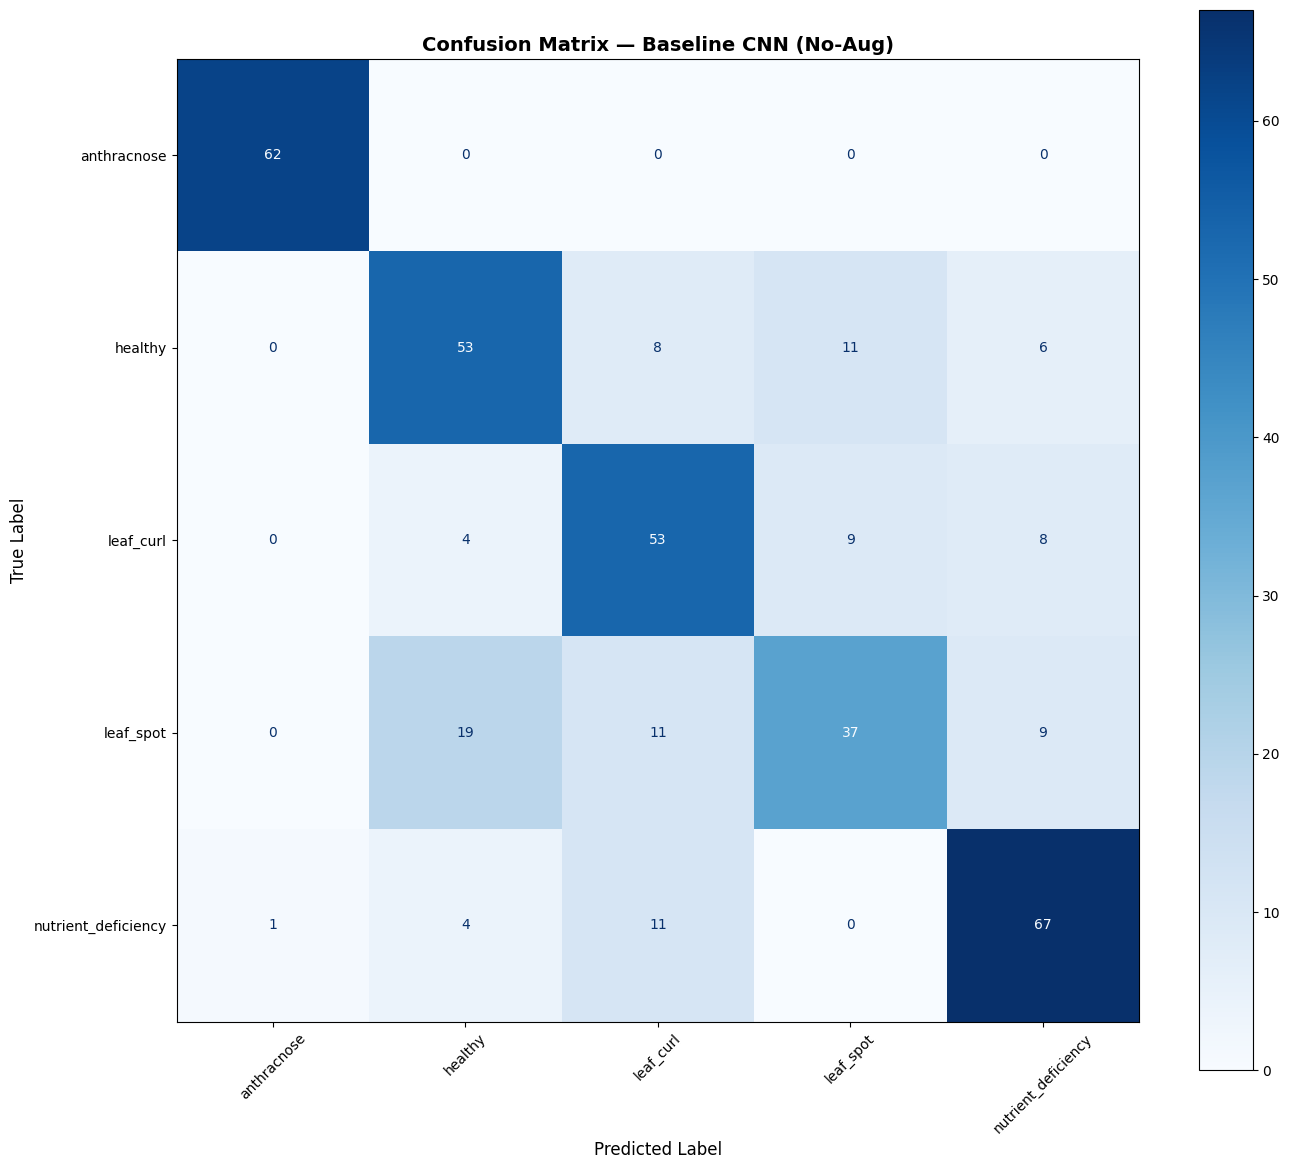

In [18]:
# ── Cell: Confusion Matrix — CNN No-Aug ──────────────────────────────────────
CNN_NOAUG_CM_PATH = f'{OUTPUT_DIR}/CNN_NoAug_CM.png'
save_confusion_matrix(
    y_true_cnn_s1, y_pred_cnn_s1,
    'Confusion Matrix — Baseline CNN (No-Aug)',
    CNN_NOAUG_CM_PATH)

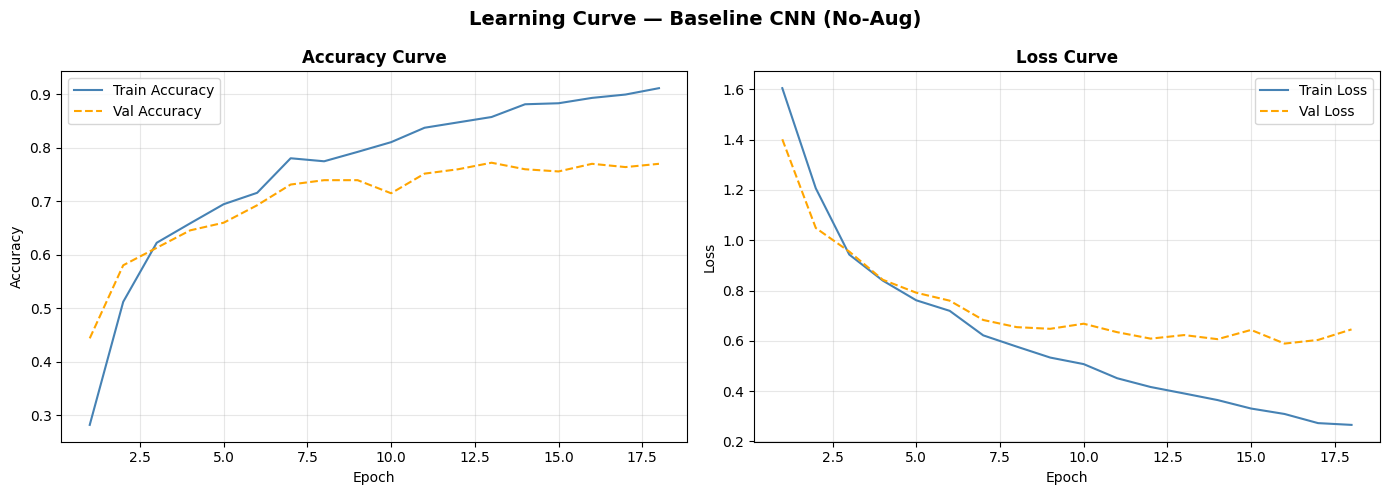

In [19]:
# ── Cell: Learning Curve — CNN No-Aug ────────────────────────────────────────
CNN_NOAUG_LC_PATH = f'{OUTPUT_DIR}/CNN_NoAug_LC.png'
save_learning_curve([hist_cnn_s1], 'Baseline CNN', 'No-Aug', CNN_NOAUG_LC_PATH)

### Model 2/4 — AlexNet (No-Aug)

In [ ]:
# ── Cell: Build & Train AlexNet — Scenario 1 ─────────────────────────────────
with strategy.scope():
    alex_s1 = build_alexnet()
    hist_alex_s1 = train_phase(alex_s1, train_ds_s1, val_ds_s1,
                                EPOCHS['alexnet'], LR, 'AlexNet_NoAug',
                                class_weight=class_weights)
alex_s1.summary()
alex_total_params = alex_s1.count_params()
print(f'\nTotal params: {alex_total_params:,}')

In [ ]:
# ── Cell: Classification Report — AlexNet No-Aug ─────────────────────────────
y_true_alex_s1, y_pred_alex_s1 = evaluate_model(
    alex_s1, test_ds_s1,
    checkpoint_path=f'{OUTPUT_DIR}/AlexNet_NoAug_best.h5')
acc_alex_s1, f1_alex_s1, rec_alex_s1 = print_metrics_report(y_true_alex_s1, y_pred_alex_s1)
print(f'Total Parameters: {alex_total_params:,}')

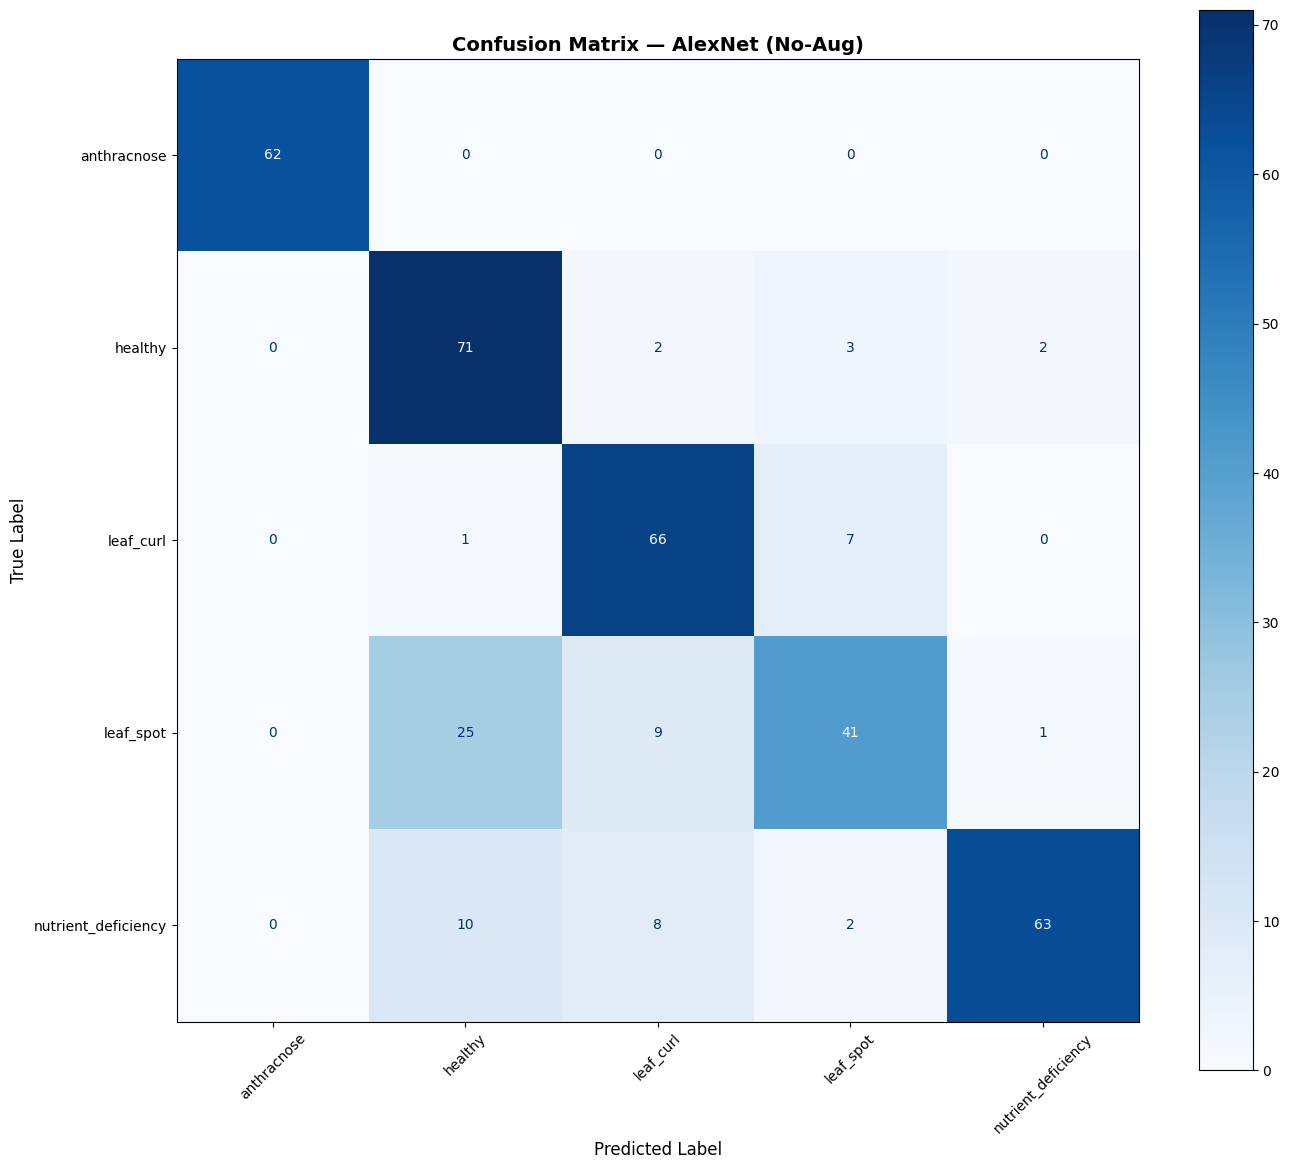

In [23]:
# ── Cell: Confusion Matrix — AlexNet No-Aug ───────────────────────────────────
ALEX_NOAUG_CM_PATH = f'{OUTPUT_DIR}/AlexNet_NoAug_CM.png'
save_confusion_matrix(
    y_true_alex_s1, y_pred_alex_s1,
    'Confusion Matrix — AlexNet (No-Aug)',
    ALEX_NOAUG_CM_PATH)

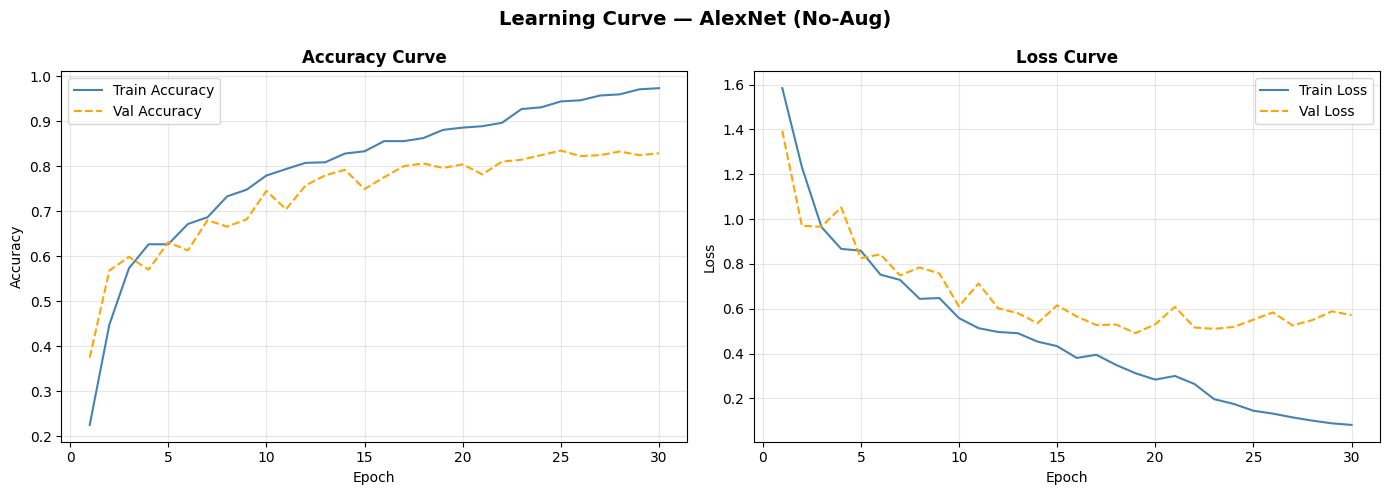

In [24]:
# ── Cell: Learning Curve — AlexNet No-Aug ────────────────────────────────────
ALEX_NOAUG_LC_PATH = f'{OUTPUT_DIR}/AlexNet_NoAug_LC.png'
save_learning_curve([hist_alex_s1], 'AlexNet', 'No-Aug', ALEX_NOAUG_LC_PATH)

### Model 3/4 — ResNet-50 (No-Aug)
Two-phase training: **Phase 1** (frozen base, 25 epochs) → **Phase 2** (unfreeze top layers, LR=1e-5, 10 epochs)

In [ ]:
# ── Cell: Build & Train ResNet-50 — Scenario 1 ───────────────────────────────
with strategy.scope():
    resnet_s1 = build_resnet50()
    # Phase 1: frozen base
    hist_resnet_s1_p1 = train_phase(resnet_s1, train_ds_s1, val_ds_s1,
                                     EPOCHS['resnet_p1'], LR, 'ResNet50_NoAug_P1',
                                     class_weight=class_weights)
    # Phase 2: unfreeze top layers
    unfreeze_top(resnet_s1, base_layer_idx=2, top_fraction=0.30)
    hist_resnet_s1_p2 = train_phase(resnet_s1, train_ds_s1, val_ds_s1,
                                     EPOCHS['resnet_p2'], LR_FT, 'ResNet50_NoAug_P2',
                                     class_weight=class_weights)
resnet_s1.summary()
resnet_total_params = resnet_s1.count_params()
print(f'\nTotal params: {resnet_total_params:,}')

In [ ]:
# ── Cell: Classification Report — ResNet-50 No-Aug ───────────────────────────
y_true_resnet_s1, y_pred_resnet_s1 = evaluate_model(
    resnet_s1, test_ds_s1,
    checkpoint_path=f'{OUTPUT_DIR}/ResNet50_NoAug_P2_best.h5')
acc_resnet_s1, f1_resnet_s1, rec_resnet_s1 = print_metrics_report(y_true_resnet_s1, y_pred_resnet_s1)
print(f'Total Parameters: {resnet_total_params:,}')

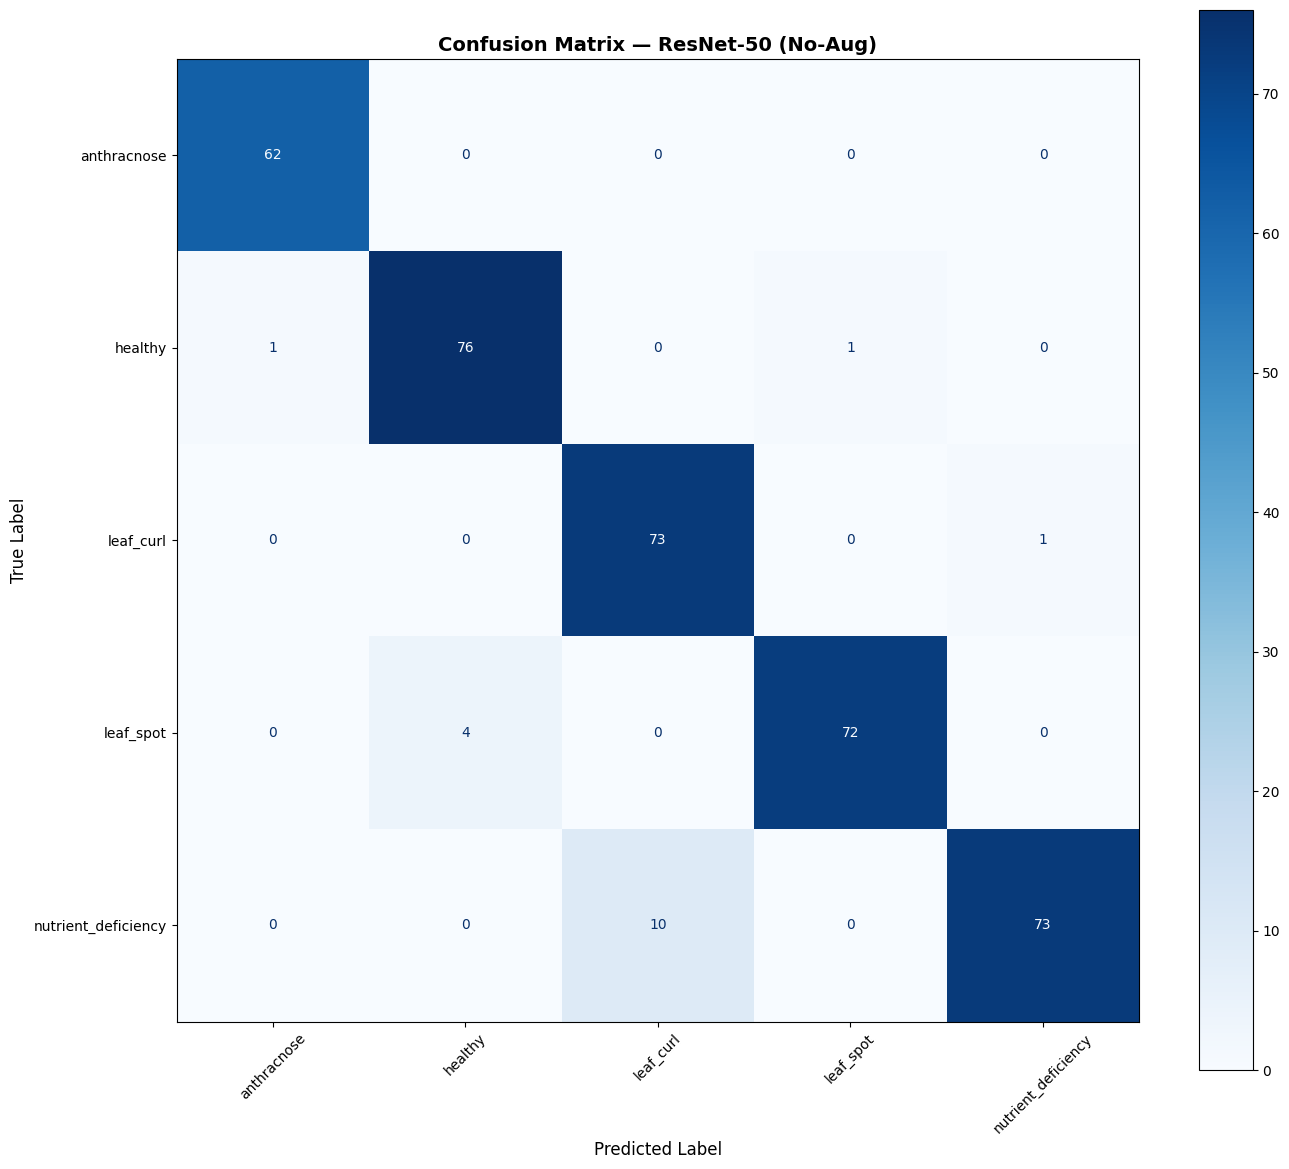

In [27]:
# ── Cell: Confusion Matrix — ResNet-50 No-Aug ────────────────────────────────
RESNET_NOAUG_CM_PATH = f'{OUTPUT_DIR}/ResNet50_NoAug_CM.png'
save_confusion_matrix(
    y_true_resnet_s1, y_pred_resnet_s1,
    'Confusion Matrix — ResNet-50 (No-Aug)',
    RESNET_NOAUG_CM_PATH)

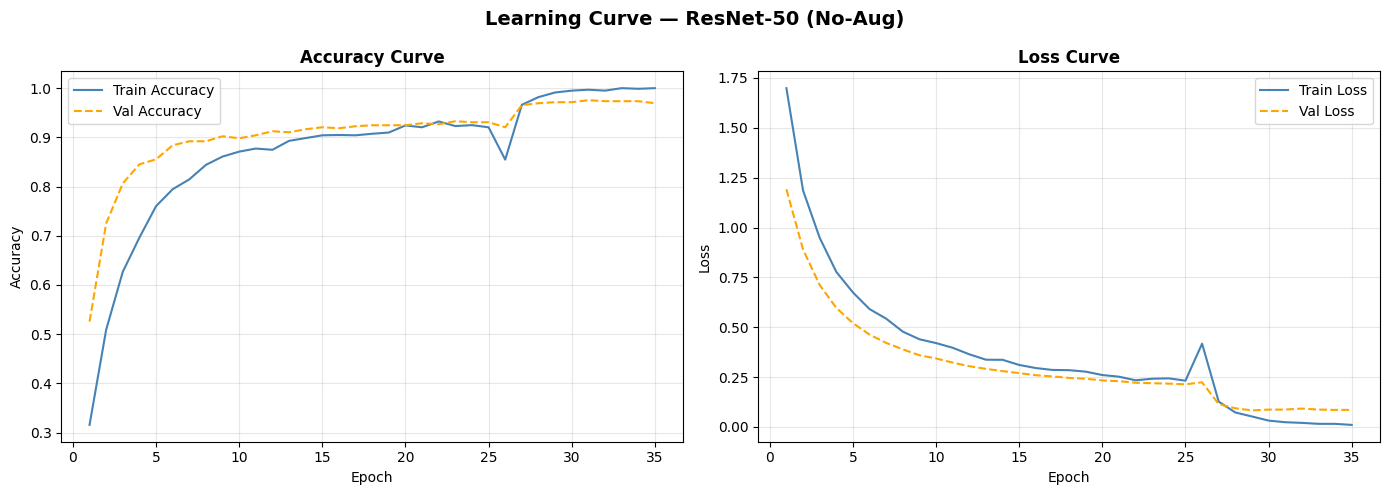

In [28]:
# ── Cell: Learning Curve — ResNet-50 No-Aug ──────────────────────────────────
RESNET_NOAUG_LC_PATH = f'{OUTPUT_DIR}/ResNet50_NoAug_LC.png'
save_learning_curve([hist_resnet_s1_p1, hist_resnet_s1_p2],
                    'ResNet-50', 'No-Aug', RESNET_NOAUG_LC_PATH)

### Model 4/4 — EfficientNetB0 (No-Aug)
Two-phase training: **Phase 1** (frozen base, 20 epochs) → **Phase 2** (unfreeze top layers, LR=1e-5, 10 epochs)

In [ ]:
# ── Cell: Build & Train EfficientNetB0 — Scenario 1 ──────────────────────────
with strategy.scope():
    eff_s1 = build_efficientnetb0()
    # Phase 1: frozen base
    hist_eff_s1_p1 = train_phase(eff_s1, train_ds_s1, val_ds_s1,
                                  EPOCHS['efficientnet_p1'], LR, 'EfficientNetB0_NoAug_P1',
                                  class_weight=class_weights)
    # Phase 2: unfreeze top layers
    unfreeze_top(eff_s1, base_layer_idx=1, top_fraction=0.30)
    hist_eff_s1_p2 = train_phase(eff_s1, train_ds_s1, val_ds_s1,
                                  EPOCHS['efficientnet_p2'], LR_FT, 'EfficientNetB0_NoAug_P2',
                                  class_weight=class_weights)
eff_s1.summary()
eff_total_params = eff_s1.count_params()
print(f'\nTotal params: {eff_total_params:,}')

In [ ]:
# ── Cell: Classification Report — EfficientNetB0 No-Aug ──────────────────────
y_true_eff_s1, y_pred_eff_s1 = evaluate_model(
    eff_s1, test_ds_s1,
    checkpoint_path=f'{OUTPUT_DIR}/EfficientNetB0_NoAug_P2_best.h5')
acc_eff_s1, f1_eff_s1, rec_eff_s1 = print_metrics_report(y_true_eff_s1, y_pred_eff_s1)
print(f'Total Parameters: {eff_total_params:,}')

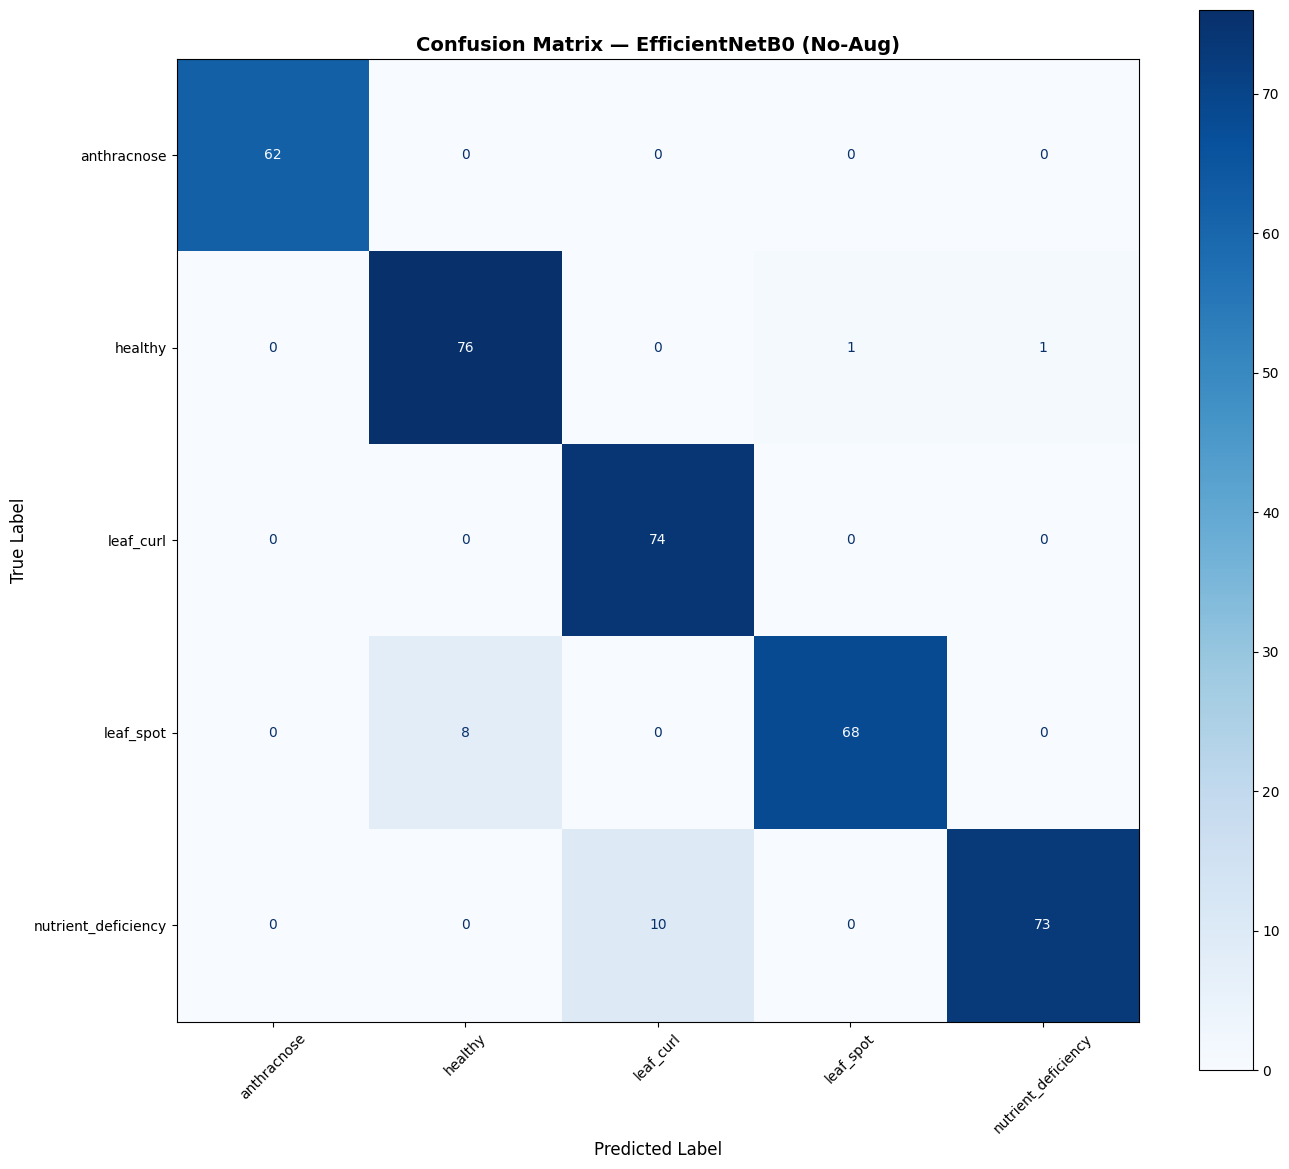

In [46]:
# ── Cell: Confusion Matrix — EfficientNetB0 No-Aug ───────────────────────────
EFF_NOAUG_CM_PATH = f'{OUTPUT_DIR}/EfficientNetB0_NoAug_CM.png'
save_confusion_matrix(
    y_true_eff_s1, y_pred_eff_s1,
    'Confusion Matrix — EfficientNetB0 (No-Aug)',
    EFF_NOAUG_CM_PATH)

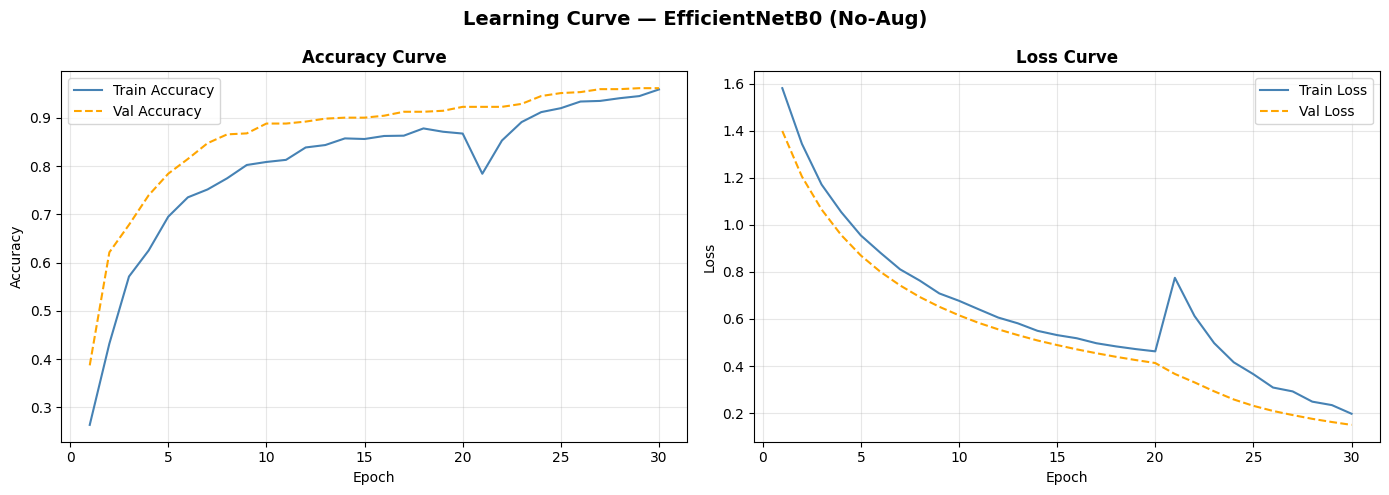

In [47]:
# ── Cell: Learning Curve — EfficientNetB0 No-Aug ─────────────────────────────
EFF_NOAUG_LC_PATH = f'{OUTPUT_DIR}/EfficientNetB0_NoAug_LC.png'
save_learning_curve([hist_eff_s1_p1, hist_eff_s1_p2],
                    'EfficientNetB0', 'No-Aug', EFF_NOAUG_LC_PATH)

In [48]:
# ── Cell: Collect Baseline (No-Aug) Metrics ───────────────────────────────────
baseline_metrics_list = [
    {'model_name': 'Baseline CNN',    'accuracy': acc_cnn_s1,    'f1_macro': f1_cnn_s1,
     'recall_macro': rec_cnn_s1,    'total_params': cnn_total_params,
     'lc': CNN_NOAUG_LC_PATH,       'cm': CNN_NOAUG_CM_PATH},
    {'model_name': 'AlexNet',         'accuracy': acc_alex_s1,   'f1_macro': f1_alex_s1,
     'recall_macro': rec_alex_s1,   'total_params': alex_total_params,
     'lc': ALEX_NOAUG_LC_PATH,      'cm': ALEX_NOAUG_CM_PATH},
    {'model_name': 'ResNet-50',       'accuracy': acc_resnet_s1, 'f1_macro': f1_resnet_s1,
     'recall_macro': rec_resnet_s1, 'total_params': resnet_total_params,
     'lc': RESNET_NOAUG_LC_PATH,    'cm': RESNET_NOAUG_CM_PATH},
    {'model_name': 'EfficientNetB0',  'accuracy': acc_eff_s1,    'f1_macro': f1_eff_s1,
     'recall_macro': rec_eff_s1,    'total_params': eff_total_params,
     'lc': EFF_NOAUG_LC_PATH,       'cm': EFF_NOAUG_CM_PATH},
]
print('baseline_metrics_list collected.')
for m in baseline_metrics_list:
    print(f"  {m['model_name']:20s}  Acc={m['accuracy']:.4f}  F1={m['f1_macro']:.4f}  Rec={m['recall_macro']:.4f}  Params={m['total_params']:,}")

baseline_metrics_list collected.
  Baseline CNN          Acc=0.7292  F1=0.7338  Rec=0.7380  Params=51,476,549
  AlexNet               Acc=0.8123  F1=0.8158  Rec=0.8201  Params=46,767,493
  ResNet-50             Acc=0.9544  F1=0.9561  Rec=0.9575  Params=23,597,957
  EfficientNetB0        Acc=0.9464  F1=0.9486  Rec=0.9497  Params=4,055,976


In [ ]:
# ── Cell: Clear GPU memory after Scenario 1 ───────────────────────────────────
import gc
tf.keras.backend.clear_session()
gc.collect()
print("GPU memory cleared after Scenario 1.")

---
## SCENARIO 2 — WITH AUGMENTATION
Transform: **Resize → RandomFlip · RandomRotation(±20°) · RandomZoom(10%) · RandomBrightness(±20%) → Normalize**

> Each model is re-initialized from scratch to prevent data leakage from Scenario 1.

In [49]:
# ── Cell: Create Augmented Datasets ──────────────────────────────────────────
train_ds_s2, val_ds_s2, test_ds_s2 = make_aug_datasets()
print('Augmented datasets created.')

Augmented datasets created.


### Model 1/4 — Baseline CNN (Aug)

In [ ]:
# ── Cell: Build & Train Baseline CNN — Scenario 2 ────────────────────────────
with strategy.scope():
    cnn_s2 = build_baseline_cnn()   # fresh initialization
    hist_cnn_s2 = train_phase(cnn_s2, train_ds_s2, val_ds_s2,
                               EPOCHS['cnn'], LR, 'CNN_Aug',
                               class_weight=class_weights)

In [ ]:
# ── Cell: Classification Report — CNN Aug ────────────────────────────────────
y_true_cnn_s2, y_pred_cnn_s2 = evaluate_model(
    cnn_s2, test_ds_s2,
    checkpoint_path=f'{OUTPUT_DIR}/CNN_Aug_best.h5')
acc_cnn_s2, f1_cnn_s2, rec_cnn_s2 = print_metrics_report(y_true_cnn_s2, y_pred_cnn_s2)
print(f'Total Parameters: {cnn_s2.count_params():,}')

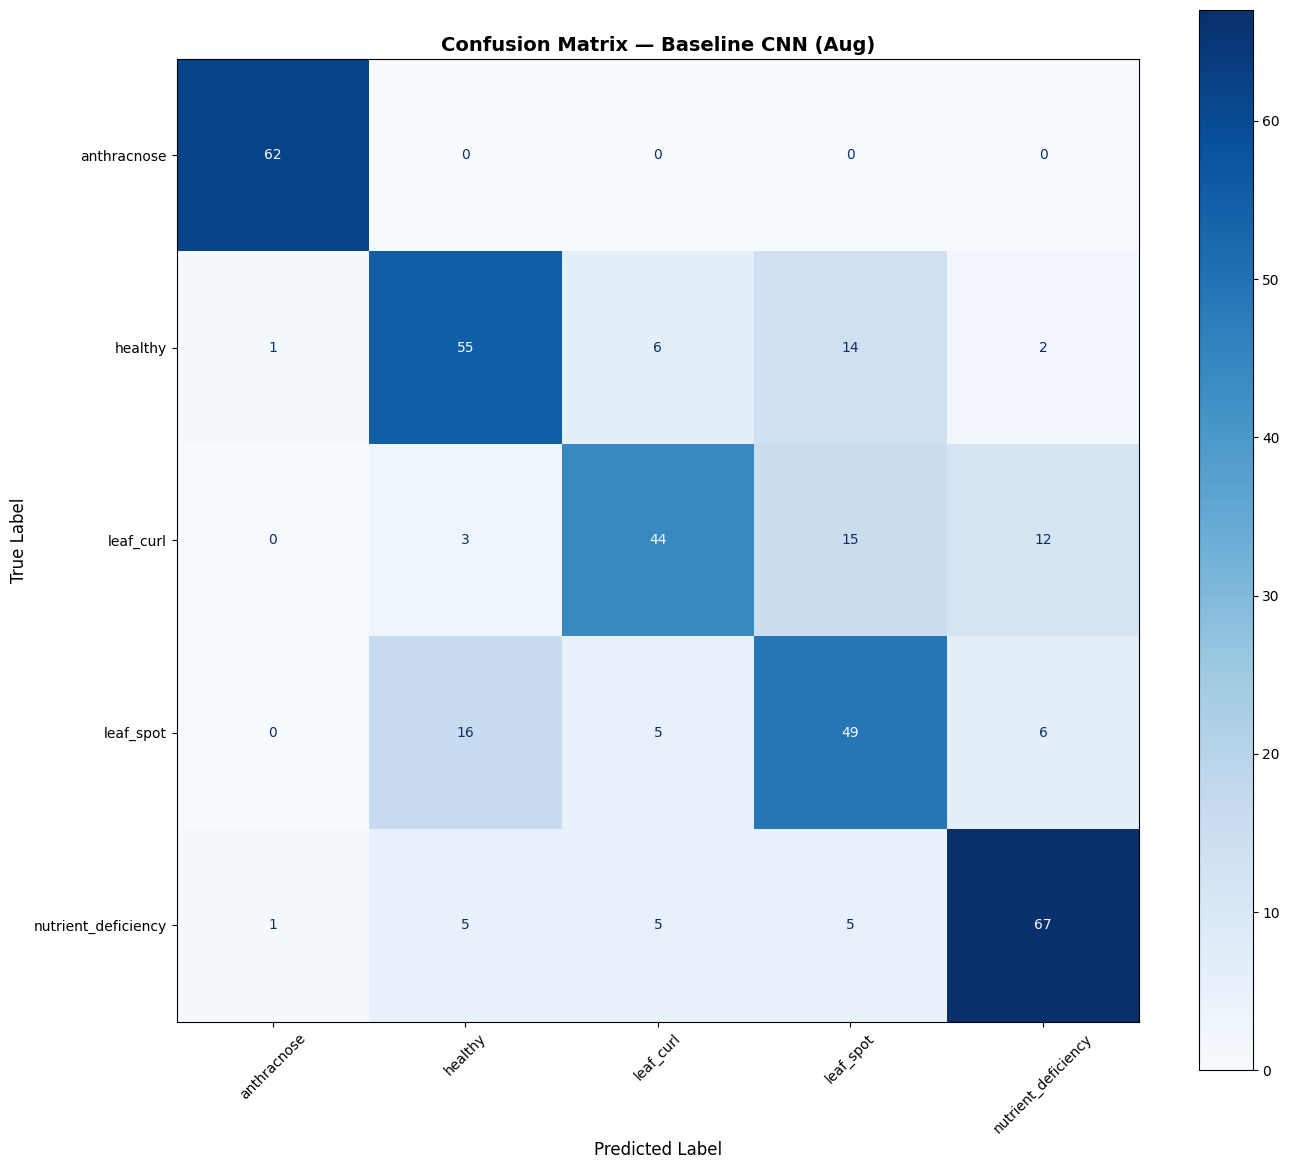

In [52]:
# ── Cell: Confusion Matrix — CNN Aug ─────────────────────────────────────────
CNN_AUG_CM_PATH = f'{OUTPUT_DIR}/CNN_Aug_CM.png'
save_confusion_matrix(
    y_true_cnn_s2, y_pred_cnn_s2,
    'Confusion Matrix — Baseline CNN (Aug)',
    CNN_AUG_CM_PATH)

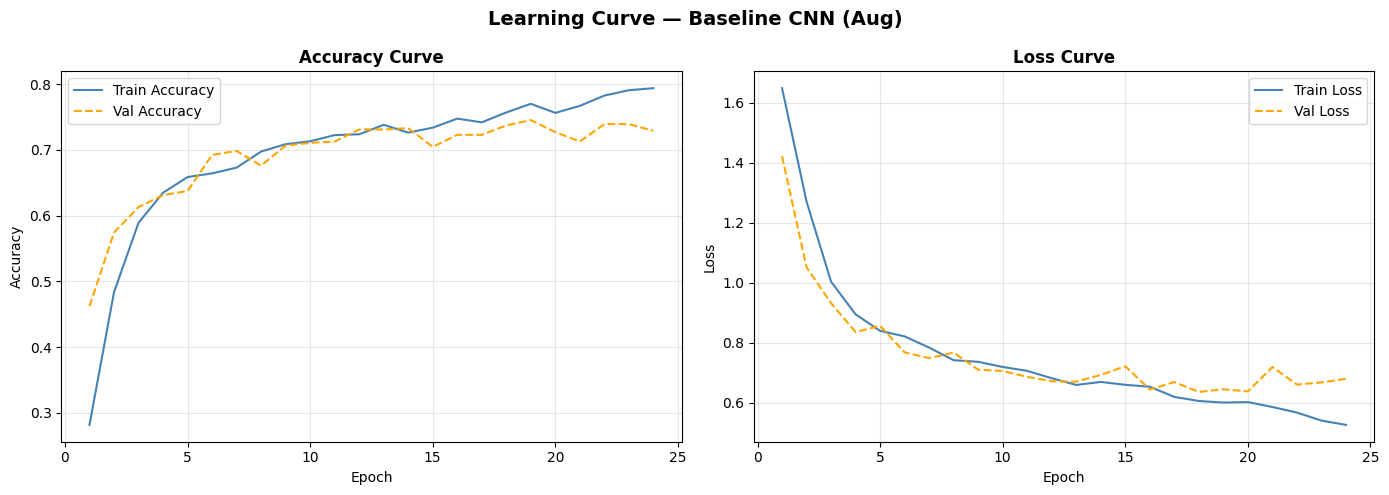

In [53]:
# ── Cell: Learning Curve — CNN Aug ───────────────────────────────────────────
CNN_AUG_LC_PATH = f'{OUTPUT_DIR}/CNN_Aug_LC.png'
save_learning_curve([hist_cnn_s2], 'Baseline CNN', 'Aug', CNN_AUG_LC_PATH)

### Model 2/4 — AlexNet (Aug)

In [ ]:
# ── Cell: Build & Train AlexNet — Scenario 2 ─────────────────────────────────
with strategy.scope():
    alex_s2 = build_alexnet()
    hist_alex_s2 = train_phase(alex_s2, train_ds_s2, val_ds_s2,
                                EPOCHS['alexnet'], LR, 'AlexNet_Aug',
                                class_weight=class_weights)

In [ ]:
# ── Cell: Classification Report — AlexNet Aug ────────────────────────────────
y_true_alex_s2, y_pred_alex_s2 = evaluate_model(
    alex_s2, test_ds_s2,
    checkpoint_path=f'{OUTPUT_DIR}/AlexNet_Aug_best.h5')
acc_alex_s2, f1_alex_s2, rec_alex_s2 = print_metrics_report(y_true_alex_s2, y_pred_alex_s2)
print(f'Total Parameters: {alex_s2.count_params():,}')

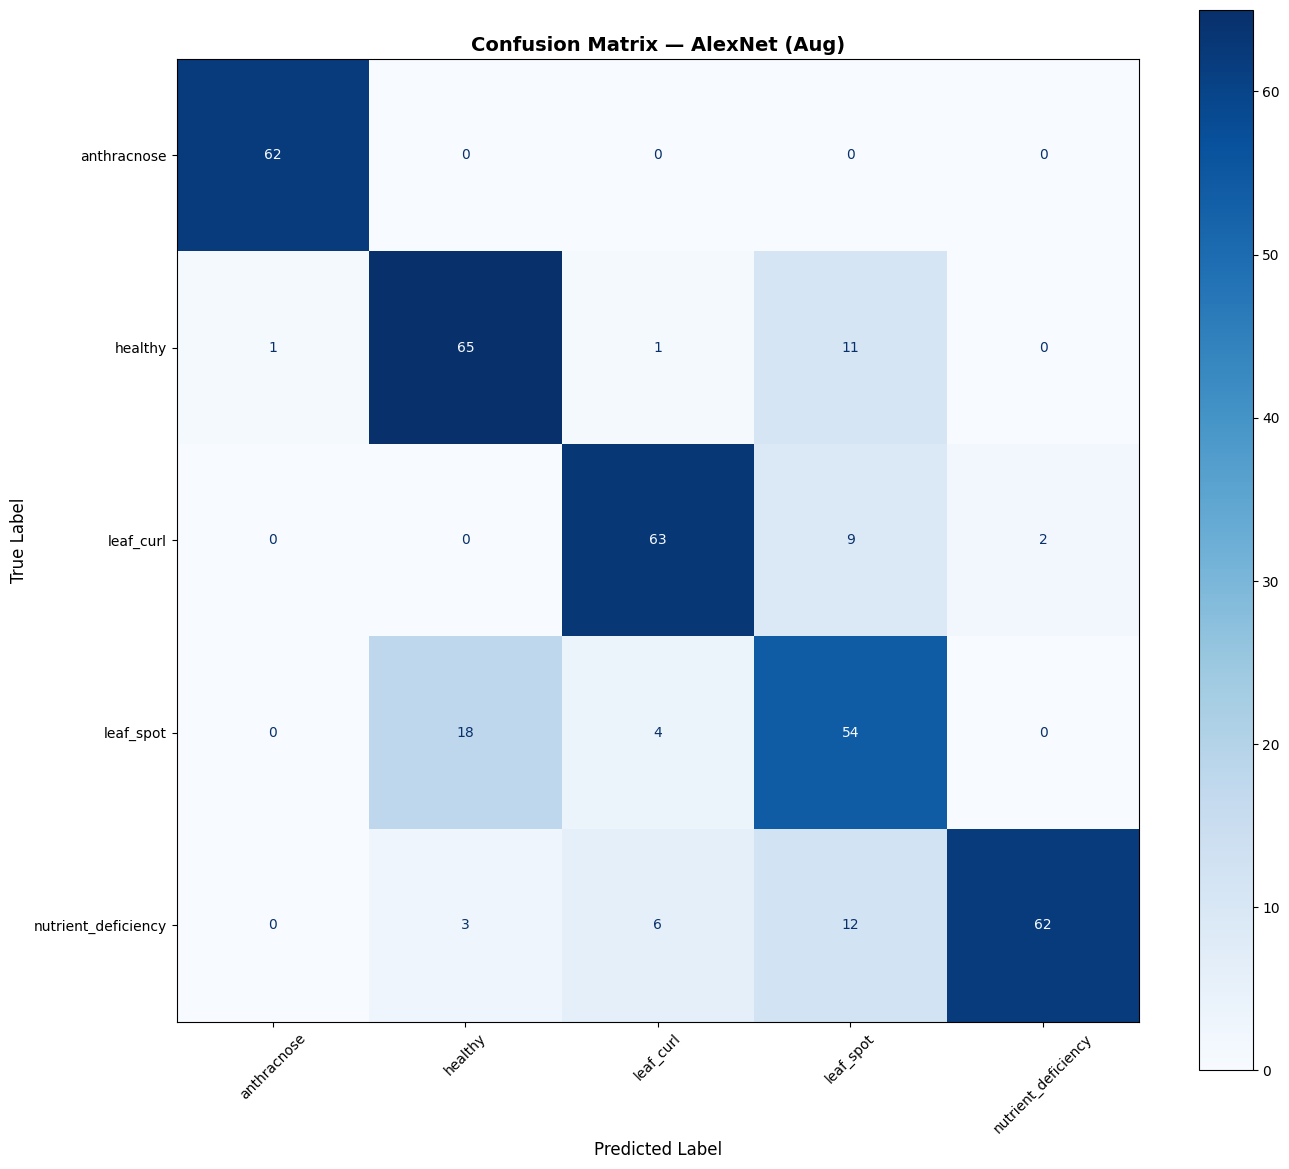

In [56]:
# ── Cell: Confusion Matrix — AlexNet Aug ─────────────────────────────────────
ALEX_AUG_CM_PATH = f'{OUTPUT_DIR}/AlexNet_Aug_CM.png'
save_confusion_matrix(
    y_true_alex_s2, y_pred_alex_s2,
    'Confusion Matrix — AlexNet (Aug)',
    ALEX_AUG_CM_PATH)

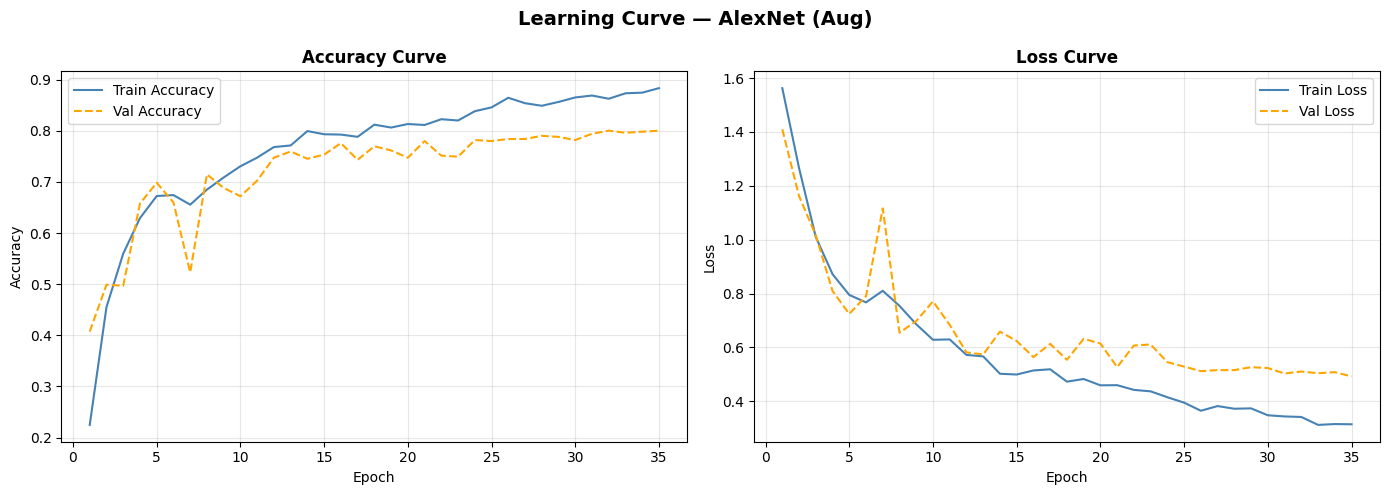

In [57]:
# ── Cell: Learning Curve — AlexNet Aug ───────────────────────────────────────
ALEX_AUG_LC_PATH = f'{OUTPUT_DIR}/AlexNet_Aug_LC.png'
save_learning_curve([hist_alex_s2], 'AlexNet', 'Aug', ALEX_AUG_LC_PATH)

### Model 3/4 — ResNet-50 (Aug)

In [ ]:
# ── Cell: Build & Train ResNet-50 — Scenario 2 ───────────────────────────────
with strategy.scope():
    resnet_s2 = build_resnet50()
    hist_resnet_s2_p1 = train_phase(resnet_s2, train_ds_s2, val_ds_s2,
                                     EPOCHS['resnet_p1'], LR, 'ResNet50_Aug_P1',
                                     class_weight=class_weights)
    unfreeze_top(resnet_s2, base_layer_idx=2, top_fraction=0.30)
    hist_resnet_s2_p2 = train_phase(resnet_s2, train_ds_s2, val_ds_s2,
                                     EPOCHS['resnet_p2'], LR_FT, 'ResNet50_Aug_P2',
                                     class_weight=class_weights)
print(f'Total params: {resnet_s2.count_params():,}')

In [ ]:
# ── Cell: Classification Report — ResNet-50 Aug ──────────────────────────────
y_true_resnet_s2, y_pred_resnet_s2 = evaluate_model(
    resnet_s2, test_ds_s2,
    checkpoint_path=f'{OUTPUT_DIR}/ResNet50_Aug_P2_best.h5')
acc_resnet_s2, f1_resnet_s2, rec_resnet_s2 = print_metrics_report(y_true_resnet_s2, y_pred_resnet_s2)
print(f'Total Parameters: {resnet_s2.count_params():,}')

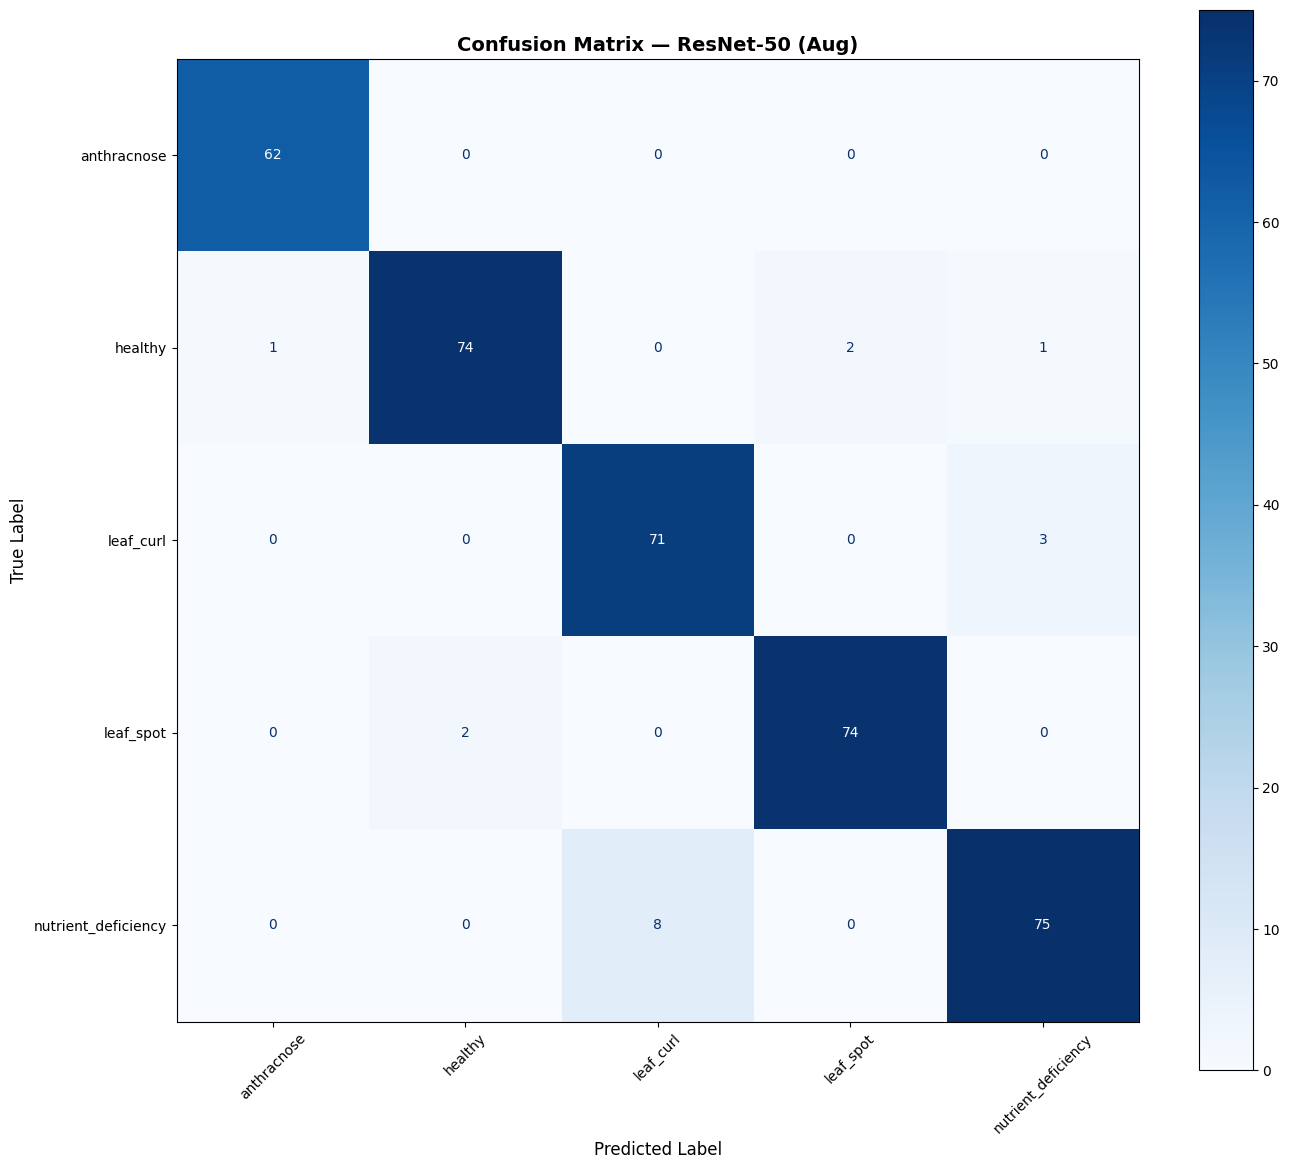

In [60]:
# ── Cell: Confusion Matrix — ResNet-50 Aug ───────────────────────────────────
RESNET_AUG_CM_PATH = f'{OUTPUT_DIR}/ResNet50_Aug_CM.png'
save_confusion_matrix(
    y_true_resnet_s2, y_pred_resnet_s2,
    'Confusion Matrix — ResNet-50 (Aug)',
    RESNET_AUG_CM_PATH)

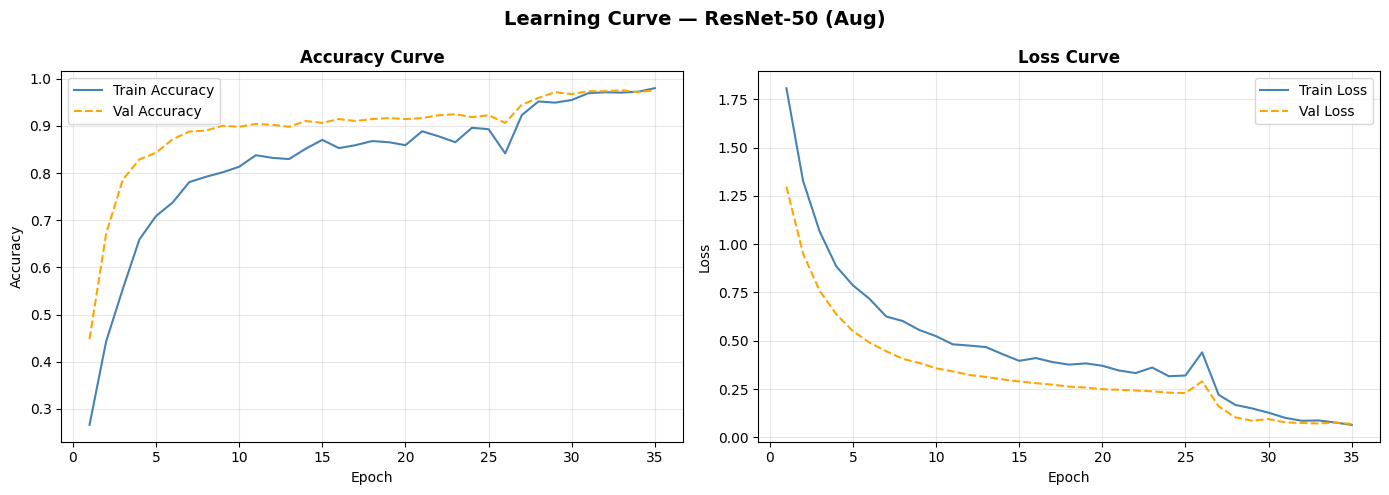

In [61]:
# ── Cell: Learning Curve — ResNet-50 Aug ─────────────────────────────────────
RESNET_AUG_LC_PATH = f'{OUTPUT_DIR}/ResNet50_Aug_LC.png'
save_learning_curve([hist_resnet_s2_p1, hist_resnet_s2_p2],
                    'ResNet-50', 'Aug', RESNET_AUG_LC_PATH)

### Model 4/4 — EfficientNetB0 (Aug)

In [ ]:
# ── Cell: Build & Train EfficientNetB0 — Scenario 2 ──────────────────────────
with strategy.scope():
    eff_s2 = build_efficientnetb0()
    hist_eff_s2_p1 = train_phase(eff_s2, train_ds_s2, val_ds_s2,
                                  EPOCHS['efficientnet_p1'], LR, 'EfficientNetB0_Aug_P1',
                                  class_weight=class_weights)
    unfreeze_top(eff_s2, base_layer_idx=1, top_fraction=0.30)
    hist_eff_s2_p2 = train_phase(eff_s2, train_ds_s2, val_ds_s2,
                                  EPOCHS['efficientnet_p2'], LR_FT, 'EfficientNetB0_Aug_P2',
                                  class_weight=class_weights)
print(f'Total params: {eff_s2.count_params():,}')

In [ ]:
# ── Cell: Classification Report — EfficientNetB0 Aug ─────────────────────────
y_true_eff_s2, y_pred_eff_s2 = evaluate_model(
    eff_s2, test_ds_s2,
    checkpoint_path=f'{OUTPUT_DIR}/EfficientNetB0_Aug_P2_best.h5')
acc_eff_s2, f1_eff_s2, rec_eff_s2 = print_metrics_report(y_true_eff_s2, y_pred_eff_s2)
print(f'Total Parameters: {eff_s2.count_params():,}')

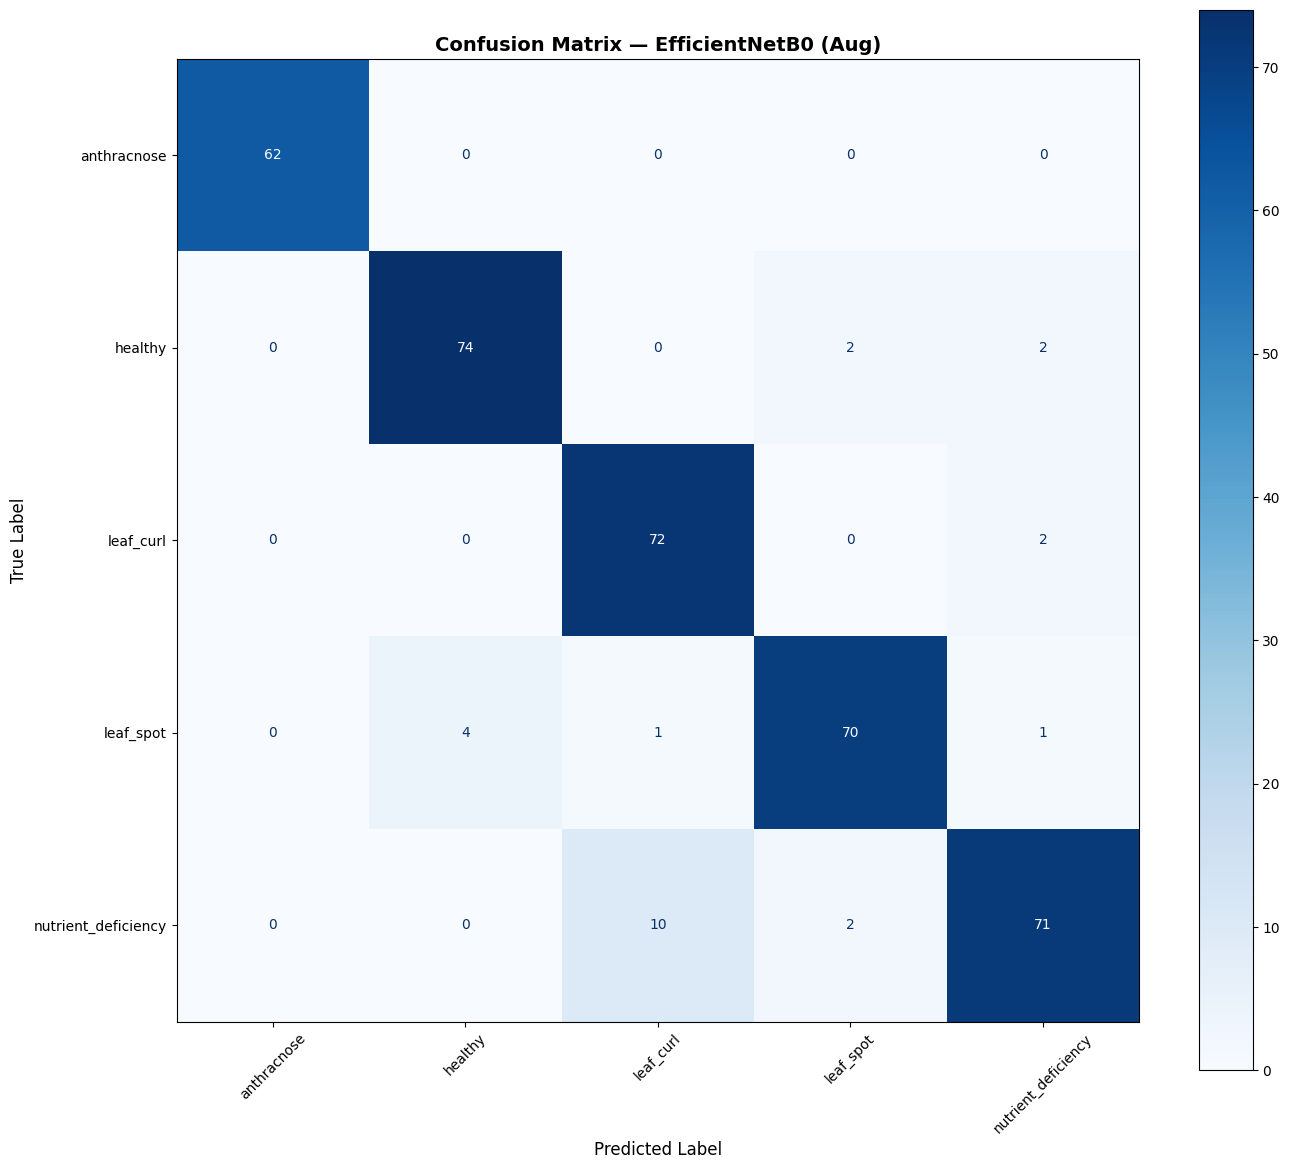

In [64]:
# ── Cell: Confusion Matrix — EfficientNetB0 Aug ───────────────────────────────
EFF_AUG_CM_PATH = f'{OUTPUT_DIR}/EfficientNetB0_Aug_CM.png'
save_confusion_matrix(
    y_true_eff_s2, y_pred_eff_s2,
    'Confusion Matrix — EfficientNetB0 (Aug)',
    EFF_AUG_CM_PATH)

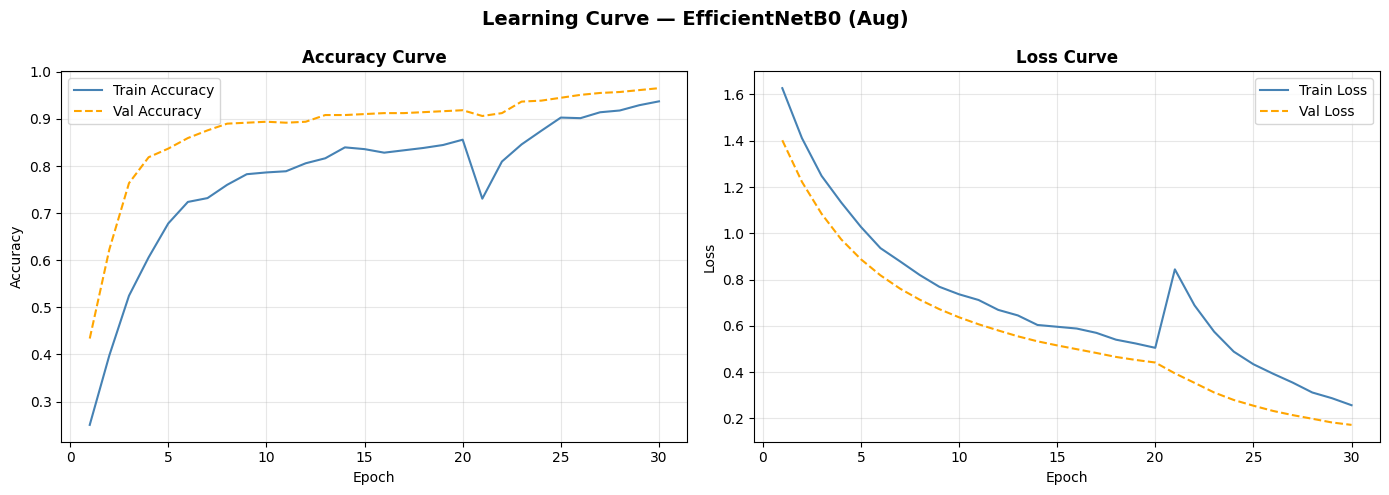

In [65]:
# ── Cell: Learning Curve — EfficientNetB0 Aug ────────────────────────────────
EFF_AUG_LC_PATH = f'{OUTPUT_DIR}/EfficientNetB0_Aug_LC.png'
save_learning_curve([hist_eff_s2_p1, hist_eff_s2_p2],
                    'EfficientNetB0', 'Aug', EFF_AUG_LC_PATH)

In [66]:
# ── Cell: Collect Augmented Metrics ──────────────────────────────────────────
aug_metrics_list = [
    {'model_name': 'Baseline CNN',   'accuracy': acc_cnn_s2,    'f1_macro': f1_cnn_s2,
     'recall_macro': rec_cnn_s2,    'total_params': cnn_s2.count_params(),
     'lc': CNN_AUG_LC_PATH,         'cm': CNN_AUG_CM_PATH},
    {'model_name': 'AlexNet',        'accuracy': acc_alex_s2,   'f1_macro': f1_alex_s2,
     'recall_macro': rec_alex_s2,   'total_params': alex_s2.count_params(),
     'lc': ALEX_AUG_LC_PATH,        'cm': ALEX_AUG_CM_PATH},
    {'model_name': 'ResNet-50',      'accuracy': acc_resnet_s2, 'f1_macro': f1_resnet_s2,
     'recall_macro': rec_resnet_s2, 'total_params': resnet_s2.count_params(),
     'lc': RESNET_AUG_LC_PATH,      'cm': RESNET_AUG_CM_PATH},
    {'model_name': 'EfficientNetB0', 'accuracy': acc_eff_s2,    'f1_macro': f1_eff_s2,
     'recall_macro': rec_eff_s2,    'total_params': eff_s2.count_params(),
     'lc': EFF_AUG_LC_PATH,         'cm': EFF_AUG_CM_PATH},
]
print('aug_metrics_list collected.')
for m in aug_metrics_list:
    print(f"  {m['model_name']:20s}  Acc={m['accuracy']:.4f}  F1={m['f1_macro']:.4f}  Rec={m['recall_macro']:.4f}  Params={m['total_params']:,}")

aug_metrics_list collected.
  Baseline CNN          Acc=0.7426  F1=0.7492  Rec=0.7503  Params=51,476,549
  AlexNet               Acc=0.8204  F1=0.8292  Rec=0.8284  Params=46,767,493
  ResNet-50             Acc=0.9544  F1=0.9562  Rec=0.9571  Params=23,597,957
  EfficientNetB0        Acc=0.9357  F1=0.9385  Rec=0.9396  Params=4,055,976


---
## EXCEL EXPORT — results_summary.xlsx
Sheet **Baseline**: 4 models × No-Aug results  
Sheet **Augmented**: 4 models × Aug results  
Columns: STT · Model · Accuracy · F1-score · Recall · Learning Curve (image) · Confusion Matrix (image) · Parameters

In [67]:
# ── Cell: Export results_summary.xlsx ────────────────────────────────────────
EXCEL_PATH = f'{OUTPUT_DIR}/results_summary.xlsx'

HEADERS    = ['STT', 'Model', 'Accuracy', 'F1-score', 'Recall',
              'Learning Curve', 'Confusion Matrix', 'Parameters']
COL_WIDTHS = [6, 30, 12, 12, 12, 38, 38, 18]
IMG_H      = 200   # row height in points for image rows

def _style_header(ws):
    fill   = PatternFill('solid', fgColor='1F4E79')
    font   = Font(bold=True, color='FFFFFF', size=11)
    border = Border(bottom=Side(style='medium', color='FFFFFF'),
                    right=Side(style='thin',   color='FFFFFF'))
    for col, hdr in enumerate(HEADERS, 1):
        c = ws.cell(row=1, column=col, value=hdr)
        c.fill, c.font, c.border = fill, font, border
        c.alignment = Alignment(horizontal='center', vertical='center', wrap_text=True)

def _write_row(ws, row_num, stt, m):
    data = [
        stt,
        f"{m['model_name']} ({PAPER_CITATION})",
        round(m['accuracy'],     4),
        round(m['f1_macro'],     4),
        round(m['recall_macro'], 4),
        '', '',
        f"{m['total_params']:,}",
    ]
    for col, val in enumerate(data, 1):
        cell = ws.cell(row=row_num, column=col, value=val)
        cell.alignment = Alignment(horizontal='center', vertical='center', wrap_text=True)
    ws.row_dimensions[row_num].height = IMG_H
    # Embed Learning Curve
    if os.path.exists(m['lc']):
        img = XLImage(m['lc'])
        img.width, img.height = 280, 190
        ws.add_image(img, f'F{row_num}')
    # Embed Confusion Matrix
    if os.path.exists(m['cm']):
        img = XLImage(m['cm'])
        img.width, img.height = 280, 190
        ws.add_image(img, f'G{row_num}')

def build_sheet(wb, sheet_name, metrics_list):
    ws = wb.create_sheet(title=sheet_name)
    for col, width in enumerate(COL_WIDTHS, 1):
        ws.column_dimensions[get_column_letter(col)].width = width
    ws.row_dimensions[1].height = 30
    _style_header(ws)
    for i, m in enumerate(metrics_list, 1):
        _write_row(ws, i + 1, i, m)

wb = Workbook()
wb.remove(wb.active)
build_sheet(wb, 'Baseline',  baseline_metrics_list)
build_sheet(wb, 'Augmented', aug_metrics_list)
wb.save(EXCEL_PATH)

print(f'[Excel] Saved: {EXCEL_PATH}')
print('\n── Baseline ──')
for m in baseline_metrics_list:
    print(f"  {m['model_name']:20s} Acc={m['accuracy']:.4f} F1={m['f1_macro']:.4f} Rec={m['recall_macro']:.4f} Params={m['total_params']:,}")
print('\n── Augmented ──')
for m in aug_metrics_list:
    print(f"  {m['model_name']:20s} Acc={m['accuracy']:.4f} F1={m['f1_macro']:.4f} Rec={m['recall_macro']:.4f} Params={m['total_params']:,}")

[Excel] Saved: /kaggle/working/results_summary.xlsx

── Baseline ──
  Baseline CNN         Acc=0.7292 F1=0.7338 Rec=0.7380 Params=51,476,549
  AlexNet              Acc=0.8123 F1=0.8158 Rec=0.8201 Params=46,767,493
  ResNet-50            Acc=0.9544 F1=0.9561 Rec=0.9575 Params=23,597,957
  EfficientNetB0       Acc=0.9464 F1=0.9486 Rec=0.9497 Params=4,055,976

── Augmented ──
  Baseline CNN         Acc=0.7426 F1=0.7492 Rec=0.7503 Params=51,476,549
  AlexNet              Acc=0.8204 F1=0.8292 Rec=0.8284 Params=46,767,493
  ResNet-50            Acc=0.9544 F1=0.9562 Rec=0.9571 Params=23,597,957
  EfficientNetB0       Acc=0.9357 F1=0.9385 Rec=0.9396 Params=4,055,976
